<a href="https://colab.research.google.com/github/SUPRAJ29DB/Brain-MRI-Tumor-Classification-CNN/blob/main/Brain-MRI-Tumor-Classification-CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

!pip -q install -U kaggle


In [6]:

import os
from getpass import getpass

token = getpass("Paste your NEW Kaggle token here: ")
os.environ["KAGGLE_API_TOKEN"] = token

print("Token entered successfully.")


Paste your NEW Kaggle token here: ··········
Token entered successfully.


In [8]:
!kaggle datasets download \
    -d masoudnickparvar/brain-tumor-mri-dataset \
    -p /content/brain_mri \
    --unzip


Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
Resuming from 44040192 bytes (120629918 bytes left)...
100% 157M/157M [00:07<00:00, 15.1MB/s]



In [9]:

from pathlib import Path

root = Path("/content/brain_mri")

for p in root.rglob("*"):
    if p.is_dir() and p.name.lower() in ("training", "testing"):
        print("Found:", p)
        print("Classes:", [
            d.name for d in p.iterdir() if d.is_dir()
        ])


Found: /content/brain_mri/Training
Classes: ['pituitary', 'glioma', 'meningioma', 'notumor']
Found: /content/brain_mri/Testing
Classes: ['pituitary', 'glioma', 'meningioma', 'notumor']


In [10]:
from pathlib import Path
root = Path("/content/brain_mri")
print("Checking dataset...")
for p in root.rglob("*"):
    if p.is_dir() and p.name.lower() in ("training", "testing"):
        print(f"\nFolder: {p}")

        for category in sorted(p.iterdir()):
            if category.is_dir():
                count = sum(
                    1 for f in category.iterdir()
                    if f.is_file() and
                    f.suffix.lower() in [".jpg", ".jpeg", ".png"]
                )
                print(f"  {category.name}: {count} images")

Checking dataset...

Folder: /content/brain_mri/Training
  glioma: 1400 images
  meningioma: 1400 images
  notumor: 1400 images
  pituitary: 1400 images

Folder: /content/brain_mri/Testing
  glioma: 400 images
  meningioma: 400 images
  notumor: 400 images
  pituitary: 400 images


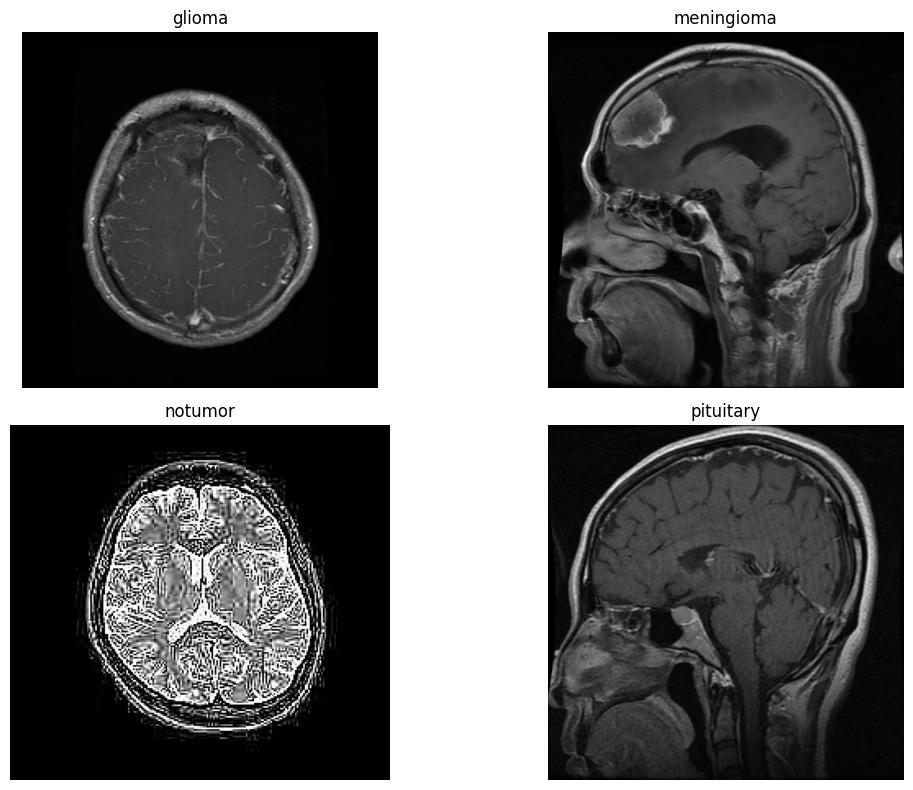

In [11]:

import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

root = Path("/content/brain_mri")

train_dir = next(
    p for p in root.rglob("*")
    if p.is_dir() and p.name.lower() == "training"
)

categories = sorted(p for p in train_dir.iterdir() if p.is_dir())

plt.figure(figsize=(12, 8))

plot_index = 1

for category in categories:
    images = [
        p for p in category.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    if images:
        image = Image.open(images[0]).convert("RGB")

        plt.subplot(2, 2, plot_index)
        plt.imshow(image)
        plt.title(category.name)
        plt.axis("off")
        plot_index += 1

plt.tight_layout()
plt.show()


In [13]:
import tensorflow as tf
from pathlib import Path
data_dir=Path("/content/brain_mri")
image_size=(128,128)
batch_size=32
seed=1337
train_dir=next(
    p for p in data_dir.rglob("*")
    if p.is_dir() and p.name.lower()=="training"
)
test_dir=next(
    p for p in data_dir.rglob("*")
    if p.is_dir() and p.name.lower()=="testing"
)
print("Training folder:", train_dir)
print("Testing folder:", test_dir)

Training folder: /content/brain_mri/Training
Testing folder: /content/brain_mri/Testing


In [15]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
    seed=seed
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
    shuffle=False
)

Found 5600 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.


In [16]:
class_names = train_ds.class_names

print("\nClasses:", class_names)
print("Number of classes:", len(class_names))

assert class_names == test_ds.class_names, (
    "Training and testing class names do not match."
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("\nDataset preparation complete!")



Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4

Dataset preparation complete!


In [18]:
from tensorflow.keras import layers, models
model=models.Sequential([
    layers.Input(shape=(128,128,3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32,3,activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128,3,activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(256,3,activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation="softmax")
])

In [19]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [20]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    epochs=15,
    validation_split=None,
    validation_data=test_ds,
    callbacks=[early_stop]
)


Epoch 1/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 18s 45ms/step - accuracy: 0.4945 - loss: 1.0546 - val_accuracy: 0.4794 - val_loss: 1.1846
Epoch 2/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.6682 - loss: 0.7942 - val_accuracy: 0.6369 - val_loss: 0.9682
Epoch 3/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.7321 - loss: 0.6799 - val_accuracy: 0.6737 - val_loss: 0.8785
Epoch 4/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.7704 - loss: 0.5967 - val_accuracy: 0.6744 - val_loss: 0.8878
Epoch 5/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 10s 45ms/step - accuracy: 0.8037 - loss: 0.5197 - val_accuracy: 0.7063 - val_loss: 0.8394
Epoch 6/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.8141 - loss: 0.4874 - val_accuracy: 0.6506 - val_loss: 0.8300
Epoch 7/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.8334 - loss: 0.4369 - val_accuracy: 0.7175 - val_loss: 0.7792
Epoch 8/15
175/175 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.8579 - loss: 0.3763 - val_ac

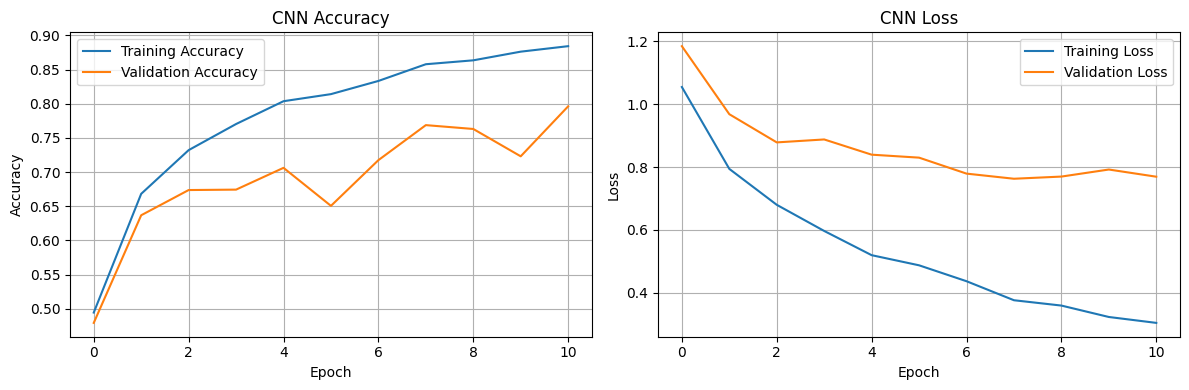

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step
Test accuracy: 76.88%

Classification Report:
              precision    recall  f1-score   support

      glioma       0.82      0.64      0.72       400
  meningioma       0.73      0.47      0.58       400
     notumor       0.68      1.00      0.81       400
   pituitary       0.87      0.96      0.92       400

    accuracy                           0.77      1600
   macro avg       0.78      0.77      0.75      1600
weighted avg       0.78      0.77      0.75      1600



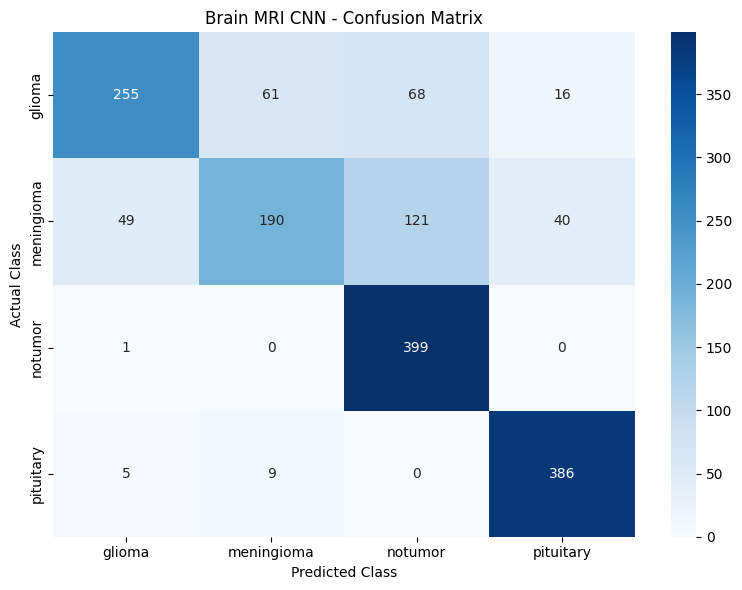

In [22]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Get actual labels from the testing dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict classes
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Brain MRI CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [23]:
model.save("/content/brain_mri_cnn.keras")
print("Model saved successfully!")


Model saved successfully!


In [24]:

from google.colab import files

files.download("/content/brain_mri_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving 41598_2023_41576_Fig1_HTML.jpg to 41598_2023_41576_Fig1_HTML.jpg


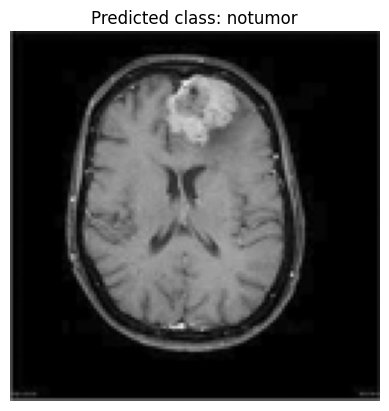

Predicted class: notumor
Model score: 92.14%


In [25]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    image = image.resize((128, 128))

    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(prediction))

    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Predicted class: {class_names[predicted_index]}")
    plt.show()

    print("Predicted class:", class_names[predicted_index])
    print(f"Model score: {prediction[predicted_index] * 100:.2f}%")


notumor: 92.14%
meningioma: 7.80%
glioma: 0.06%
pituitary: 0.00%


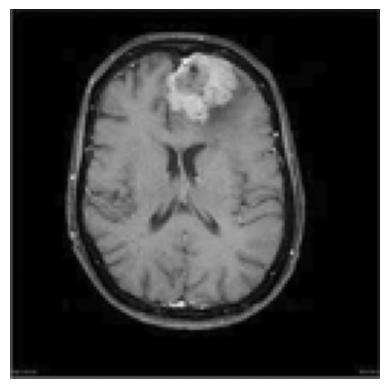

In [26]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Use the uploaded image file
filename = "41598_2023_41576_Fig1_HTML.jpg"

image = Image.open(filename).convert("RGB")
image = image.resize((128, 128))

image_array = np.array(image, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

probabilities = model.predict(image_array, verbose=0)[0]

for class_name, score in sorted(
    zip(class_names, probabilities),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{class_name}: {score * 100:.2f}%")

plt.imshow(image)
plt.axis("off")
plt.show()


In [1]:

import os

print("Dataset exists:", os.path.exists("/content/brain_mri"))
print("Trained model exists:", os.path.exists("/content/brain_mri_cnn.keras"))


Dataset exists: False
Trained model exists: False
